# Quantum Error Correction

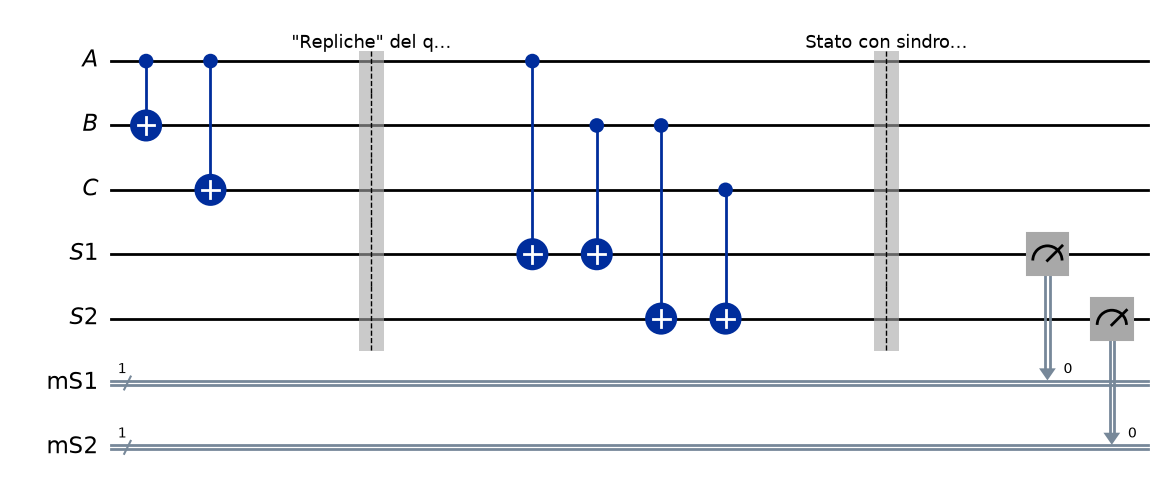

In [9]:
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

# Dove A, B e C sono le "repliche" utilizzate per il qubit
A, B, C = 0,1,2

# Ancilla Qubit utilizzati per il controllo del sistema
S1, S2 = 3,4

qA,qB,qC = (QuantumRegister(1,n) for n in "ABC")
qS1 = QuantumRegister(1, "S1")
qS2 = QuantumRegister(1, "S2")

mS1 = ClassicalRegister(1, "mS1")
mS2 = ClassicalRegister(1, "mS2")

qc = QuantumCircuit(qA,qB,qC,qS1,qS2, mS1, mS2)

# Generazione delle "Copie"
qc.cx(A,B)
qc.cx(A,C)

qc.barrier(label="\"Repliche\" del qubit")

qc.cx(A,S1)
qc.cx(B,S1)

qc.cx(B,S2)
qc.cx(C,S2)

qc.barrier(label="Stato con sindrome impostata")

qc.measure(S1, mS1)
qc.measure(S2, mS2)

fig = qc.draw(output='mpl',style='iqp')
display(fig)
plt.close(fig)

# Decoder

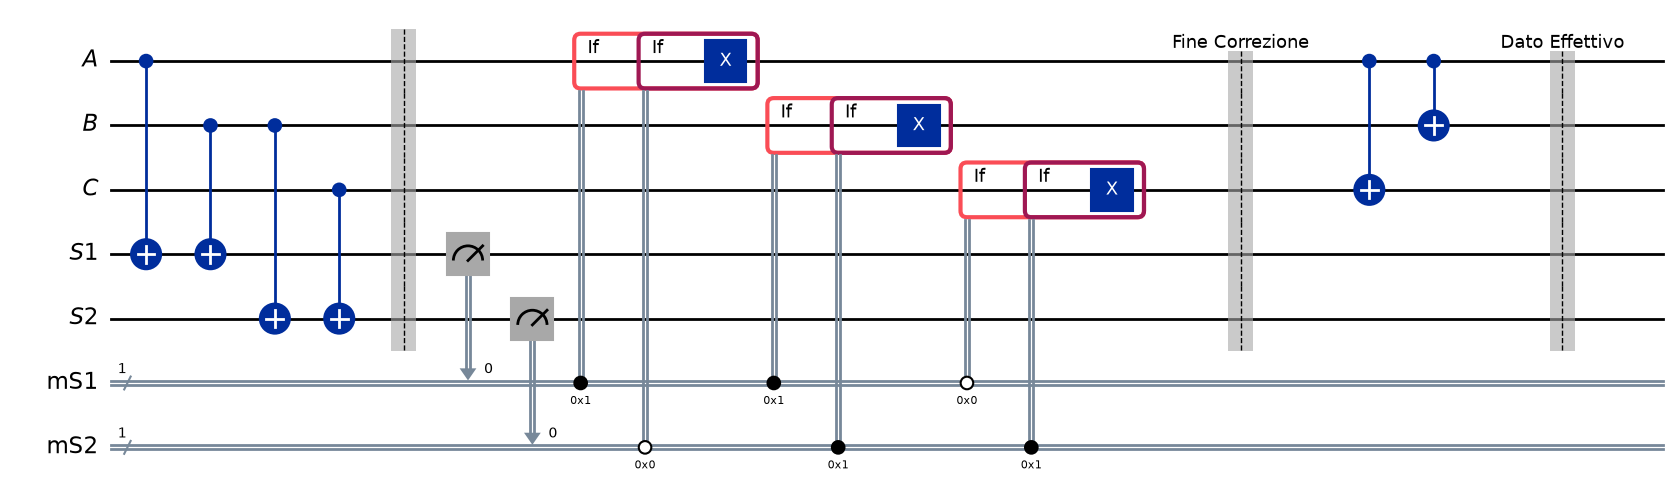

In [11]:
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

A,B,C = 0,1,2
S1, S2 = 3,4

qA,qB,qC = (QuantumRegister(1,n) for n in "ABC")
qS1 = QuantumRegister(1,"S1")
qS2 = QuantumRegister(1,"S2")

mS1 = ClassicalRegister(1,"mS1")
mS2 = ClassicalRegister(1,"mS2")

qc = QuantumCircuit(qA,qB,qC,qS1,qS2,mS1,mS2)

# Setting delle ancille
qc.cx(A,S1)
qc.cx(B,S1)

qc.cx(B,S2)
qc.cx(C,S2)
#qc.barrier(label="Settaggio Ancille")

qc.barrier()

qc.measure(S1, mS1)
qc.measure(S2, mS2)

# mS1 mS2 = 10 -> X su A
with qc.if_test((mS1, 1)):
    with qc.if_test((mS2, 0)):
        qc.x(A)

# mS1 mS2 = 11 -> X su B
with qc.if_test((mS1, 1)):
    with qc.if_test((mS2, 1)):
        qc.x(B)

# mS1 mS2 = 01 -> X su C
with qc.if_test((mS1, 0)):
    with qc.if_test((mS2, 1)):
        qc.x(C)

qc.barrier(label="Fine Correzione")

qc.cx(A,C)
qc.cx(A,B)

qc.barrier(label="Dato Effettivo")

fig = qc.draw(output='mpl',style='iqp')
display(fig)
plt.close(fig)

# Phase Flip

## Encoding

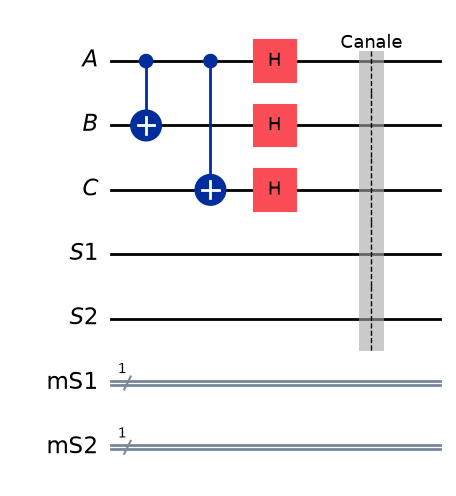

In [14]:
# Encoding
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

A,B,C = 0,1,2
S1, S2 = 3,4

qA,qB,qC = (QuantumRegister(1,n) for n in "ABC")
qS1 = QuantumRegister(1,"S1")
qS2 = QuantumRegister(1,"S2")

mS1 = ClassicalRegister(1,"mS1")
mS2 = ClassicalRegister(1,"mS2")

qc = QuantumCircuit(qA,qB,qC,qS1,qS2,mS1,mS2)

# Setting delle ancille
qc.cx(A,B)
qc.cx(A,C)

qc.h(A)
qc.h(B)
qc.h(C)

qc.barrier(label="Canale")

fig = qc.draw(output='mpl',style='iqp')
display(fig)
plt.close(fig)

## Decoding

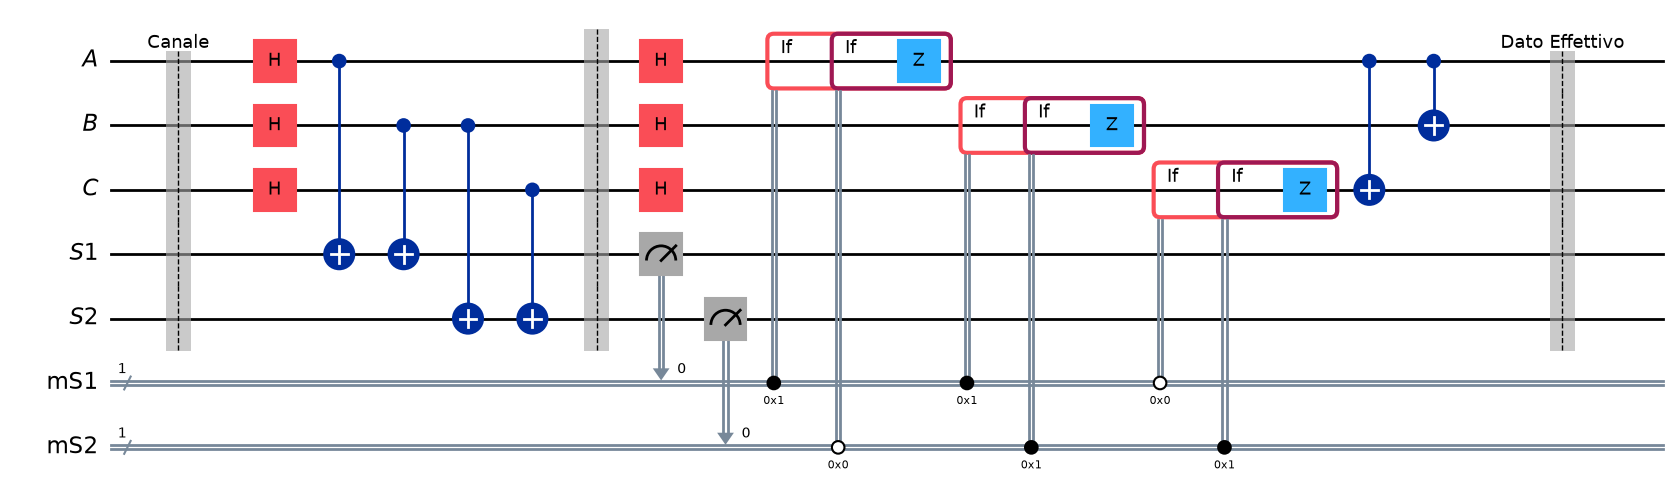

In [22]:
# Decoding
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

A,B,C = 0,1,2
S1, S2 = 3,4

qA,qB,qC = (QuantumRegister(1,n) for n in "ABC")
qS1 = QuantumRegister(1,"S1")
qS2 = QuantumRegister(1,"S2")

mS1 = ClassicalRegister(1,"mS1")
mS2 = ClassicalRegister(1,"mS2")

qc = QuantumCircuit(qA,qB,qC,qS1,qS2,mS1,mS2)

qc.barrier(label="Canale")

qc.h(A)
qc.h(B)
qc.h(C)

# Setting delle ancille
qc.cx(A,S1)
qc.cx(B,S1)

qc.cx(B,S2)
qc.cx(C,S2)
#qc.barrier(label="Settaggio Ancille")

qc.barrier()

qc.measure(S1, mS1)
qc.measure(S2, mS2)

qc.h(A)
qc.h(B)
qc.h(C)

# mS1 mS2 = 10 -> X su A
with qc.if_test((mS1, 1)):
    with qc.if_test((mS2, 0)):
        qc.z(A)

# mS1 mS2 = 11 -> X su B
with qc.if_test((mS1, 1)):
    with qc.if_test((mS2, 1)):
        qc.z(B)

# mS1 mS2 = 01 -> X su C
with qc.if_test((mS1, 0)):
    with qc.if_test((mS2, 1)):
        qc.z(C)



qc.cx(A,C)
qc.cx(A,B)

qc.barrier(label="Dato Effettivo")

fig = qc.draw(output='mpl',style='iqp')
display(fig)
plt.close(fig)

# Prove di Funzionamento Iterative

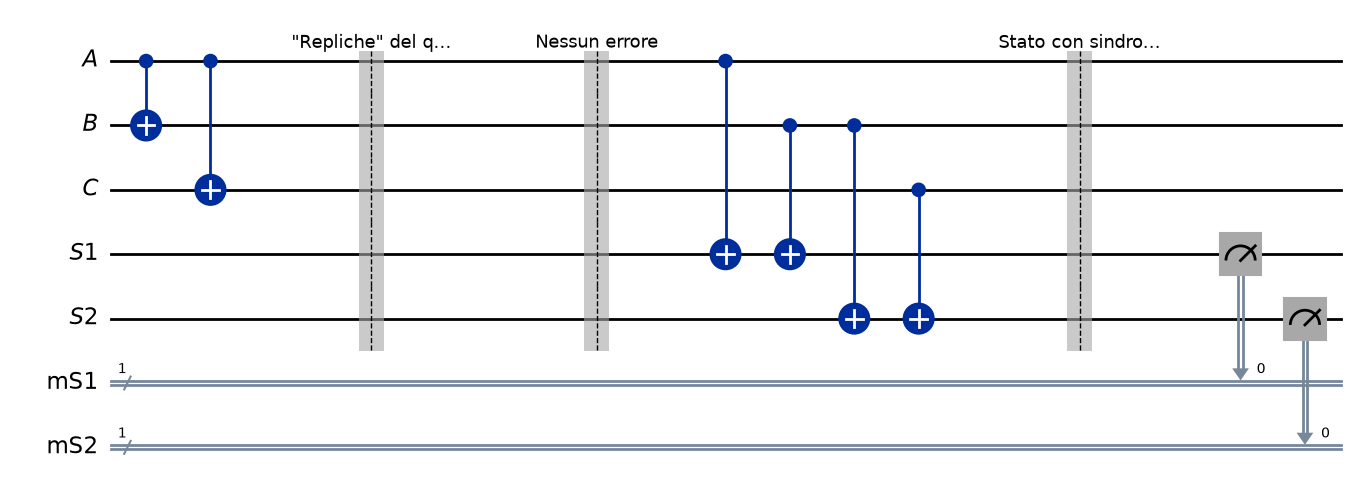

Nessun errore -> {'0 0': 1024}


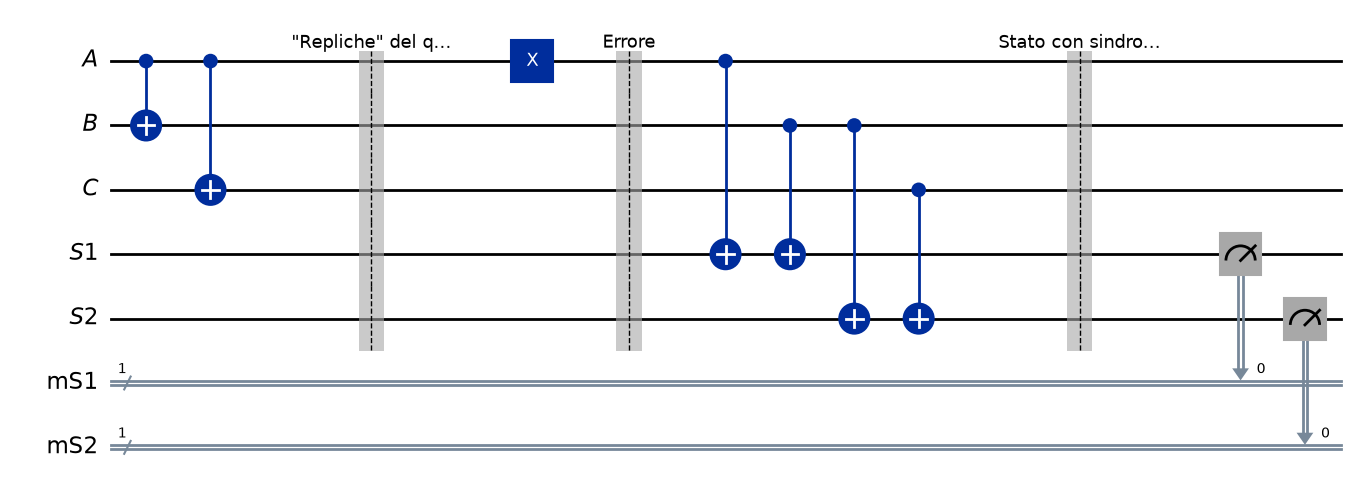

Errore su A -> {'0 1': 1024}


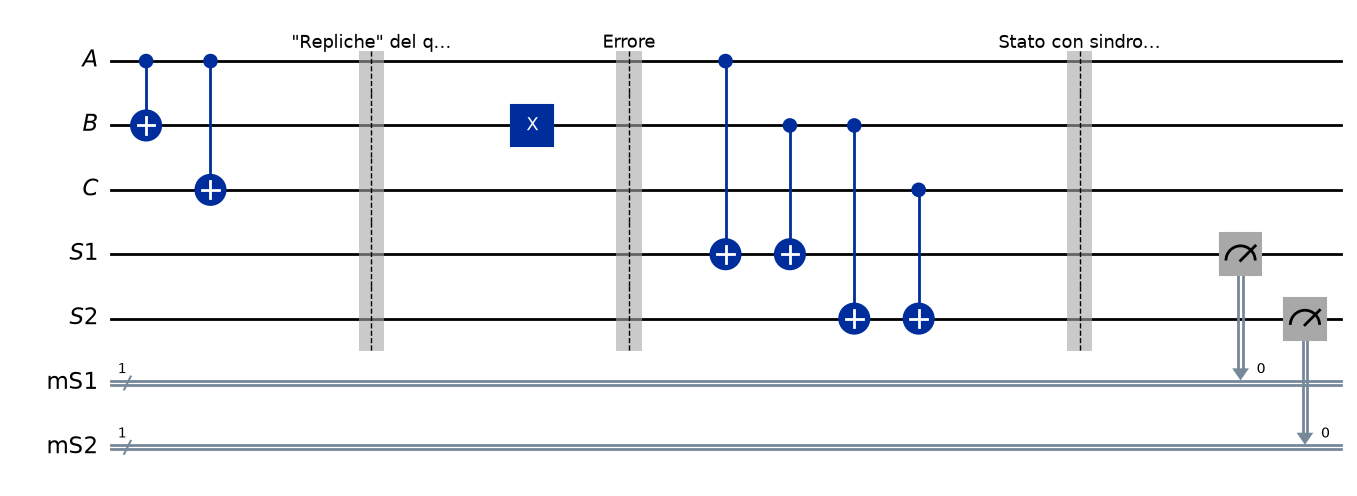

Errore su B -> {'1 1': 1024}


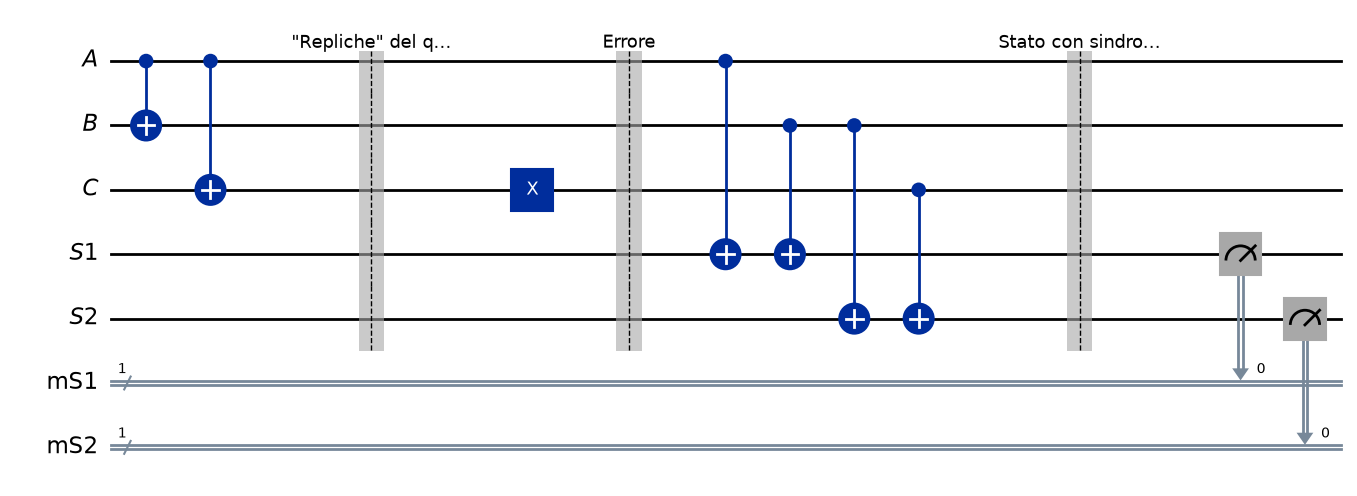

Errore su C -> {'1 0': 1024}


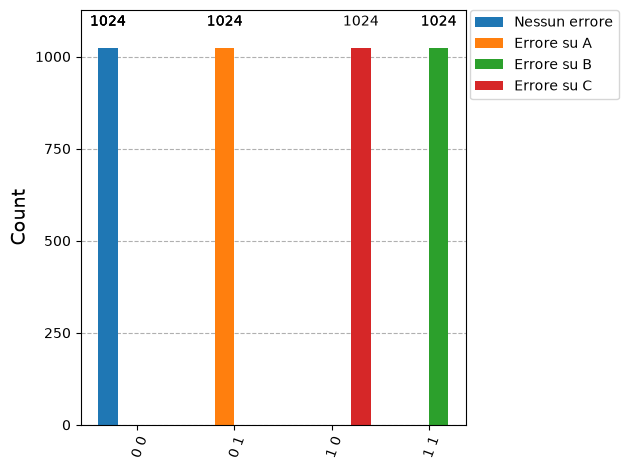

In [10]:
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

A, B, C = 0, 1, 2
S1, S2 = 3, 4

def build_circuit(errore=None):
    qA, qB, qC = (QuantumRegister(1, n) for n in "ABC")
    qS1 = QuantumRegister(1, "S1")
    qS2 = QuantumRegister(1, "S2")
    mS1 = ClassicalRegister(1, "mS1")
    mS2 = ClassicalRegister(1, "mS2")
    qc = QuantumCircuit(qA, qB, qC, qS1, qS2, mS1, mS2)

    # (opzionale) stato di partenza non banale per A, es. qc.ry(1.0, A)

    # Codifica
    qc.cx(A, B)
    qc.cx(A, C)
    qc.barrier(label='"Repliche" del qubit')

    # Errore di bit-flip iniettato
    if errore is not None:
        qc.x(errore)
    qc.barrier(label="Errore" if errore is not None else "Nessun errore")

    # Estrazione della sindrome
    qc.cx(A, S1)
    qc.cx(B, S1)
    qc.cx(B, S2)
    qc.cx(C, S2)
    qc.barrier(label="Stato con sindrome impostata")

    qc.measure(S1, mS1)
    qc.measure(S2, mS2)
    return qc

prove = {
    "Nessun errore": None,
    "Errore su A": A,
    "Errore su B": B,
    "Errore su C": C,
}

sim = AerSimulator()
risultati = {}

for nome, q in prove.items():
    qc = build_circuit(q)
    fig = qc.draw(output="mpl", style="iqp")
    display(fig)
    plt.close(fig)

    counts = sim.run(transpile(qc, sim), shots=1024).result().get_counts()
    risultati[nome] = counts
    print(nome, "->", counts)

display(plot_histogram(list(risultati.values()), legend=list(risultati.keys())))